# Workshop 3 — Part A (Steps 1 & 2): Exploratory Data Analysis (EDA), Data Cleaning & Schema Harmonization

## Objective
Perform comprehensive Exploratory Data Analysis (EDA) across the 5 historical World Happiness Report datasets (`2015.csv` – `2019.csv`), identify data quality issues and schema discrepancies, justify all cleaning decisions, and produce a harmonized analytical dataset (`data/processed/happiness_unified.csv`) ready for both Machine Learning training and Kafka event streaming.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

# Resolve raw data path whether running from project root or notebooks/
RAW_DIR = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
PROCESSED_DIR = Path("../data/processed") if Path("../data").exists() else Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

YEARS = [2015, 2016, 2017, 2018, 2019]
raw_datasets = {year: pd.read_csv(RAW_DIR / f"{year}.csv") for year in YEARS}

for year, df in raw_datasets.items():
    print(f"Year {year}: {df.shape[0]} rows x {df.shape[1]} columns")

Year 2015: 158 rows x 12 columns
Year 2016: 157 rows x 13 columns
Year 2017: 155 rows x 12 columns
Year 2018: 156 rows x 9 columns
Year 2019: 156 rows x 9 columns


---
## Step 1 — Exploratory Data Analysis (EDA)

### 1.1 Schema Differences & Inconsistent Column Names Across Years
The five CSV files do not share the same schema or column naming convention:
- **2015 & 2016** use human-readable names with spaces and parentheses (e.g., `Economy (GDP per Capita)`, `Health (Life Expectancy)`, `Trust (Government Corruption)`) and include `Region` and `Dystopia Residual`.
- **2017** uses dot-separated names (`Happiness.Score`, `Economy..GDP.per.Capita.`, `Whisker.high`, `Whisker.low`) and omits `Region`.
- **2018 & 2019** adopt new terminology (`Score`, `Country or region`, `GDP per capita`, `Social support`, `Healthy life expectancy`, `Freedom to make life choices`, `Perceptions of corruption`) and drop `Dystopia Residual` and confidence intervals.

In [2]:
schema_comparison = pd.DataFrame({
    year: pd.Series(df.columns) for year, df in raw_datasets.items()
})
print("Column Names by Year:")
print(schema_comparison.fillna("-").to_string(index=True))

Column Names by Year:
                             2015                           2016                           2017                          2018                          2019
0                         Country                        Country                        Country                  Overall rank                  Overall rank
1                          Region                         Region                 Happiness.Rank             Country or region             Country or region
2                  Happiness Rank                 Happiness Rank                Happiness.Score                         Score                         Score
3                 Happiness Score                Happiness Score                   Whisker.high                GDP per capita                GDP per capita
4                  Standard Error      Lower Confidence Interval                    Whisker.low                Social support                Social support
5        Economy (GDP per Capita)      Upp

### 1.2 Data Types, Missing Values & Duplicated Records
Below we inspect data types, null counts, full-row duplicates, and country-level duplicates per year.

In [3]:
quality_summary = []
for year, df in raw_datasets.items():
    country_col = [c for c in df.columns if "Country" in c][0]
    total_missing = int(df.isna().sum().sum())
    missing_cols = df.isna().sum()
    missing_detail = ", ".join([f"{col} ({cnt})" for col, cnt in missing_cols.items() if cnt > 0]) or "None"
    quality_summary.append({
        "Year": year,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Full-Row Duplicates": int(df.duplicated().sum()),
        "Duplicate Countries": int(df[country_col].duplicated().sum()),
        "Total Missing Values": total_missing,
        "Missing Columns Detail": missing_detail
    })

quality_df = pd.DataFrame(quality_summary)
print(quality_df.to_string(index=False))

print("\nInspecting the exact row with a missing value in 2018:")
df_2018 = raw_datasets[2018]
print(df_2018[df_2018.isna().any(axis=1)].to_string(index=False))

 Year  Rows  Columns  Full-Row Duplicates  Duplicate Countries  Total Missing Values        Missing Columns Detail
 2015   158       12                    0                    0                     0                          None
 2016   157       13                    0                    0                     0                          None
 2017   155       12                    0                    0                     0                          None
 2018   156        9                    0                    0                     1 Perceptions of corruption (1)
 2019   156        9                    0                    0                     0                          None

Inspecting the exact row with a missing value in 2018:
 Overall rank    Country or region  Score  GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
           20 United Arab Emirates  6.774           2.096           0.776             

### 1.3 Entity Consistency Analysis (Inconsistent Country Names Across Years)
Because `country` is used as the **Kafka partition key** in Part B and the **`dim_country` dimension key** in Part C, inconsistent spelling of country names across years would fragment partitions and create duplicate dimension entries. Let's inspect countries whose names changed across 2015–2019.

In [4]:
country_years = {}
for year, df in raw_datasets.items():
    country_col = [c for c in df.columns if "Country" in c][0]
    for c in df[country_col].astype(str).str.strip().unique():
        country_years.setdefault(c, []).append(year)

print("Detected naming variations across years:")
variations = [
    ("Hong Kong", "Hong Kong S.A.R., China"),
    ("Taiwan", "Taiwan Province of China"),
    ("Trinidad and Tobago", "Trinidad & Tobago"),
    ("North Cyprus", "Northern Cyprus"),
    ("Macedonia", "North Macedonia"),
    ("Somaliland region", "Somaliland Region"),
]
for v1, v2 in variations:
    print(f"  - {v1!r} {country_years.get(v1)} vs {v2!r} {country_years.get(v2)}")

Detected naming variations across years:
  - 'Hong Kong' [2015, 2016, 2018, 2019] vs 'Hong Kong S.A.R., China' [2017]
  - 'Taiwan' [2015, 2016, 2018, 2019] vs 'Taiwan Province of China' [2017]
  - 'Trinidad and Tobago' [2015, 2016, 2017] vs 'Trinidad & Tobago' [2018, 2019]
  - 'North Cyprus' [2015, 2016, 2017] vs 'Northern Cyprus' [2018, 2019]
  - 'Macedonia' [2015, 2016, 2017, 2018] vs 'North Macedonia' [2019]
  - 'Somaliland region' [2015] vs 'Somaliland Region' [2016]


---
## Step 2 — Data Cleaning and Harmonization

### 2.1 Unified Schema Proposal
To integrate all five years (2015–2019) and comply with the **Part B Kafka Event Contract**, we define the following unified schema:

| Unified Column | Data Type | Source Columns (2015–2016 / 2017 / 2018–2019) | Role |
|---|---|---|---|
| `country` | `string` | `Country` / `Country` / `Country or region` | Entity identifier & Kafka Partition Key |
| `year` | `int64` | Extracted from file year (`2015`–`2019`) | Temporal identifier (`dim_date`) |
| `gdp` | `float64` | `Economy (GDP per Capita)` / `Economy..GDP.per.Capita.` / `GDP per capita` | ML Feature 1 |
| `family` | `float64` | `Family` / `Family` / `Social support` | ML Feature 2 |
| `health` | `float64` | `Health (Life Expectancy)` / `Health..Life.Expectancy.` / `Healthy life expectancy` | ML Feature 3 |
| `freedom` | `float64` | `Freedom` / `Freedom` / `Freedom to make life choices` | ML Feature 4 |
| `generosity` | `float64` | `Generosity` / `Generosity` / `Generosity` | ML Feature 5 |
| `corruption` | `float64` | `Trust (Government Corruption)` / `Trust..Government.Corruption.` / `Perceptions of corruption` | ML Feature 6 |
| `happiness_score` | `float64` | `Happiness Score` / `Happiness.Score` / `Score` | Target Variable (`actual_happiness_score`) |

### Justification of Cleaning & Harmonization Decisions
1. **Dropping Non-Uniform & Leakage Columns**:
   - `Happiness Rank` / `Overall rank`, `Standard Error`, `Lower/Upper Confidence Interval`, `Whisker.high/low` are direct functions of the target variable and cause **target leakage**.
   - `Dystopia Residual` is only present in 2015–2017 and, by definition of the World Happiness Report, satisfies `Happiness Score = GDP + Family + Health + Freedom + Generosity + Corruption + Dystopia Residual`. Including it would cause severe target leakage and schema failure on 2018–2019 records.
   - `Region` is only present in 2015–2016 and is not part of the downstream Kafka Event Contract.
2. **Handling Missing Values (`Perceptions of corruption` in 2018 for `United Arab Emirates`)**:
   - Rather than dropping the `United Arab Emirates (2018)` record (which would lose a valid country observation), we impute the single missing `corruption` value using the **historical mean of United Arab Emirates across the other 4 years (`0.31198`)**, with a fallback to the global median (`SimpleImputer(strategy='median')`) inside our scikit-learn Pipeline so real-time inference remains resilient.
3. **Standardizing Country Names**:
   - We strip whitespace and map the 6 variant country names to canonical names (`Hong Kong`, `Taiwan`, `Trinidad and Tobago`, `North Cyprus`, `North Macedonia`, `Somaliland Region`), reducing distinct country keys from 170 to 164.

In [5]:
SCHEMA_MAP = {
    2015: {
        "Country": "country",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp",
        "Family": "family",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
    },
    2016: {
        "Country": "country",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp",
        "Family": "family",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
    },
    2017: {
        "Country": "country",
        "Happiness.Score": "happiness_score",
        "Economy..GDP.per.Capita.": "gdp",
        "Family": "family",
        "Health..Life.Expectancy.": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust..Government.Corruption.": "corruption",
    },
    2018: {
        "Country or region": "country",
        "Score": "happiness_score",
        "GDP per capita": "gdp",
        "Social support": "family",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption",
    },
    2019: {
        "Country or region": "country",
        "Score": "happiness_score",
        "GDP per capita": "gdp",
        "Social support": "family",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption",
    },
}

COUNTRY_FIXES = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "Macedonia": "North Macedonia",
    "Somaliland region": "Somaliland Region",
}

UNIFIED_COLS = [
    "country", "year", "gdp", "family", "health",
    "freedom", "generosity", "corruption", "happiness_score"
]
NUMERIC_COLS = ["gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]

harmonized_frames = []
for year in YEARS:
    df_year = raw_datasets[year].rename(columns=SCHEMA_MAP[year])[list(SCHEMA_MAP[year].values())].copy()
    df_year["year"] = int(year)
    df_year["country"] = df_year["country"].astype(str).str.strip().replace(COUNTRY_FIXES)
    for col in NUMERIC_COLS:
        df_year[col] = pd.to_numeric(df_year[col], errors="coerce").astype("float64")
    harmonized_frames.append(df_year[UNIFIED_COLS])

unified_df = pd.concat(harmonized_frames, ignore_index=True)

# Impute UAE 2018 missing corruption using UAE's historical mean across 2015, 2016, 2017, 2019
uae_hist_mean = unified_df.loc[
    (unified_df["country"] == "United Arab Emirates") & (unified_df["corruption"].notna()),
    "corruption"
].mean()
unified_df["corruption"] = unified_df.groupby("country")["corruption"].transform(
    lambda s: s.fillna(s.mean())
)
unified_df["corruption"] = unified_df["corruption"].fillna(unified_df["corruption"].median())

print(f"Unified dataset shape: {unified_df.shape}")
print(f"Imputed UAE 2018 corruption value: {uae_hist_mean:.5f}")
print("\nNull count after cleaning:")
print(unified_df.isna().sum())

Unified dataset shape: (782, 9)
Imputed UAE 2018 corruption value: 0.31198

Null count after cleaning:
country            0
year               0
gdp                0
family             0
health             0
freedom            0
generosity         0
corruption         0
happiness_score    0
dtype: int64


### 2.2 Outlier Analysis (IQR Method & Boxplots)
We evaluate potential outliers across all numerical variables using the Interquartile Range ($1.5 \times \text{IQR}$) rule.
- **Observation**: Variables such as `corruption` (67 high-end outliers, e.g., Rwanda, Singapore, Denmark, Qatar where trust in government is unusually high compared to the global median) and `generosity` (17 high-end outliers, e.g., Myanmar) exhibit right-skewed distributions. `family` shows 10 low-end outliers (conflict-affected countries such as Central African Republic and Syria).
- **Decision**: These values are **legitimate country-level socioeconomic measurements**, not sensor or data-entry errors. Removing them would bias the model against high-trust or crisis-affected nations when streaming historical events in Part B. Therefore, we **retain all 782 records** and use `StandardScaler` + ensemble/linear models.

         Column   Min     Q1  Median     Q3    Max  IQR Lower  IQR Upper  Outliers Count
            gdp 0.000 0.6065  0.9822 1.2362 2.0960    -0.3380     2.1807               0
         family 0.000 0.8694  1.1247 1.3272 1.6440     0.1825     2.0141              10
         health 0.000 0.4402  0.6473 0.8080 1.1410    -0.1115     1.3597               0
        freedom 0.000 0.3098  0.4310 0.5310 0.7240    -0.0221     0.8628               0
     generosity 0.000 0.1300  0.2020 0.2788 0.8381    -0.0932     0.5021              17
     corruption 0.000 0.0542  0.0910 0.1562 0.5519    -0.0987     0.3092              68
happiness_score 2.693 4.5098  5.3220 6.1895 7.7690     1.9901     8.7091               0


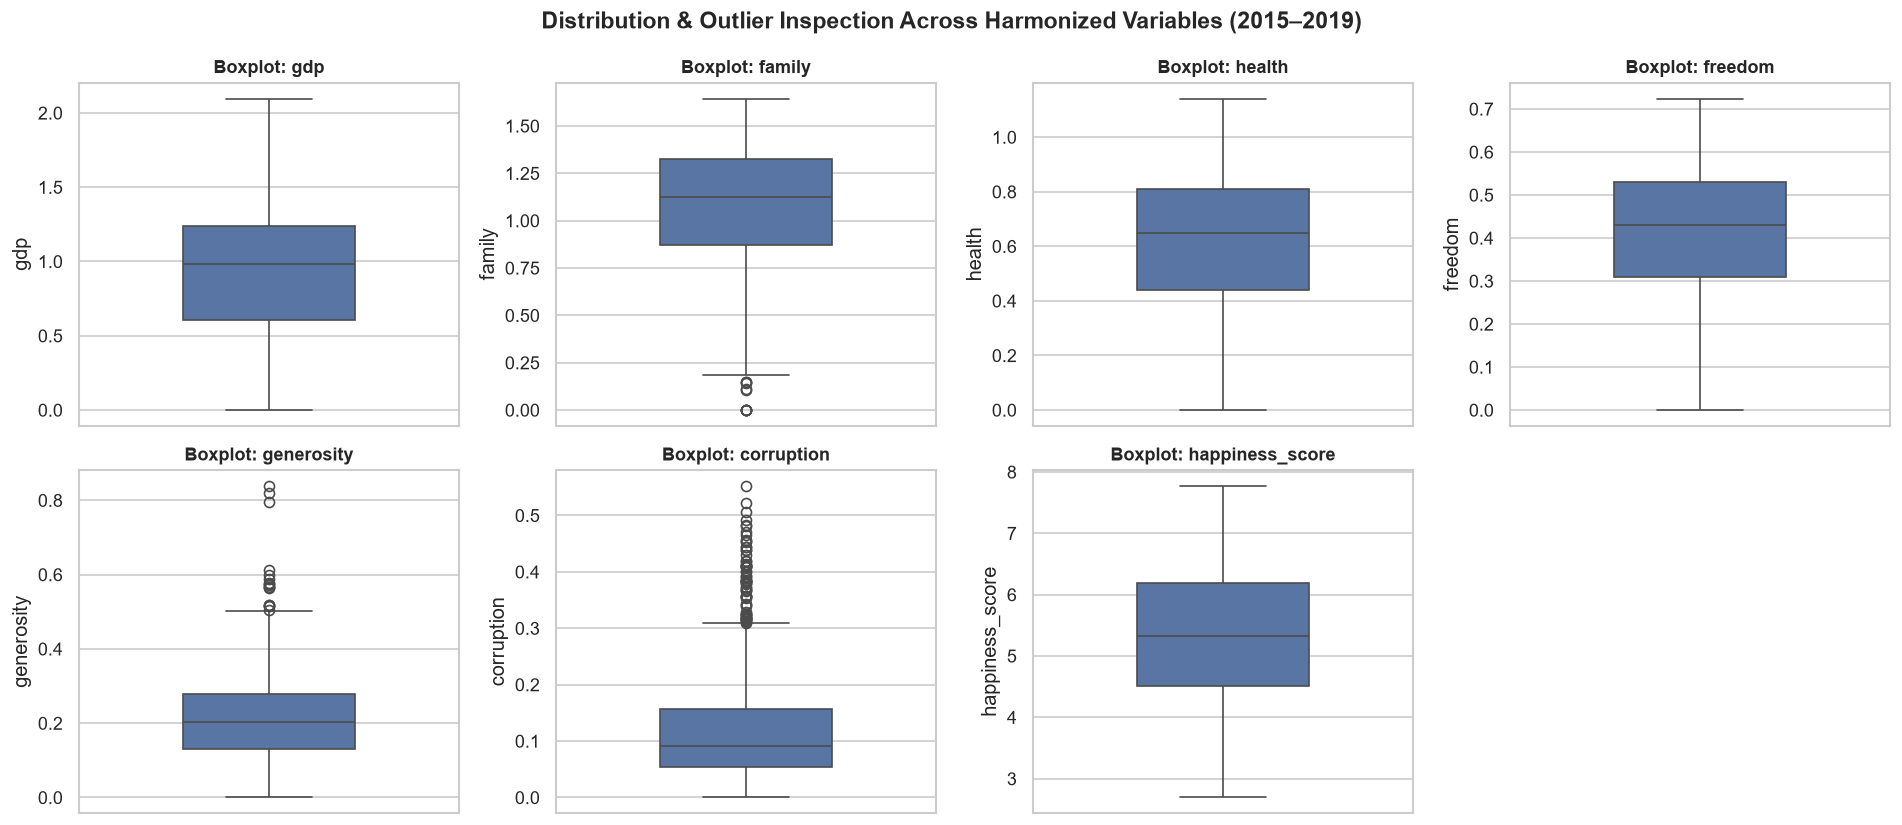

In [6]:
outlier_rows = []
for col in NUMERIC_COLS:
    q1 = unified_df[col].quantile(0.25)
    q3 = unified_df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((unified_df[col] < lower) | (unified_df[col] > upper)).sum())
    outlier_rows.append({
        "Column": col,
        "Min": round(unified_df[col].min(), 4),
        "Q1": round(q1, 4),
        "Median": round(unified_df[col].median(), 4),
        "Q3": round(q3, 4),
        "Max": round(unified_df[col].max(), 4),
        "IQR Lower": round(lower, 4),
        "IQR Upper": round(upper, 4),
        "Outliers Count": n_out
    })

print(pd.DataFrame(outlier_rows).to_string(index=False))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for idx, col in enumerate(NUMERIC_COLS):
    sns.boxplot(y=unified_df[col], ax=axes[idx], color="#4C72B0", width=0.45)
    axes[idx].set_title(f"Boxplot: {col}", fontsize=11, fontweight="bold")
axes[-1].axis("off")
plt.suptitle("Distribution & Outlier Inspection Across Harmonized Variables (2015–2019)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Save Unified Dataset
We persist the harmonized dataset to `data/processed/happiness_unified.csv` for Step 3–4 (Feature Engineering & Model Training) and Part B (Kafka Producer streaming simulation).

In [7]:
from sklearn.model_selection import train_test_split

# Tag 70% Train vs 30% Test split (random_state=42) for downstream streaming evaluation transparency
_, test_indices = train_test_split(unified_df.index, test_size=0.30, random_state=42)
unified_df["is_test_set"] = unified_df.index.isin(test_indices)

output_csv = PROCESSED_DIR / "happiness_unified.csv"
unified_df.to_csv(output_csv, index=False)
print(f"Successfully saved unified dataset to: {output_csv} ({len(unified_df)} rows)")
print("Split distribution (is_test_set):", unified_df["is_test_set"].value_counts().to_dict())
print("\nSample rows:")
print(unified_df.head(10).to_string(index=False))

Successfully saved unified dataset to: data\processed\happiness_unified.csv (782 rows)
Split distribution (is_test_set): {False: 547, True: 235}

Sample rows:
    country  year     gdp  family  health  freedom  generosity  corruption  happiness_score  is_test_set
Switzerland  2015 1.39651 1.34951 0.94143  0.66557     0.29678     0.41978            7.587        False
    Iceland  2015 1.30232 1.40223 0.94784  0.62877     0.43630     0.14145            7.561        False
    Denmark  2015 1.32548 1.36058 0.87464  0.64938     0.34139     0.48357            7.527         True
     Norway  2015 1.45900 1.33095 0.88521  0.66973     0.34699     0.36503            7.522        False
     Canada  2015 1.32629 1.32261 0.90563  0.63297     0.45811     0.32957            7.427        False
    Finland  2015 1.29025 1.31826 0.88911  0.64169     0.23351     0.41372            7.406        False
Netherlands  2015 1.32944 1.28017 0.89284  0.61576     0.47610     0.31814            7.378         True
 